# Expliquer un détecteur d'intrusion

**Jeu de données.** CIC-IDS2017, flux réseau du lundi au vendredi.

**Question.** Un classifieur binaire, normal contre attaque, apprend-il des comportements d'intrusion, ou des particularités de la collecte ?

**Décision officielle.** XGBoost, entraîné du lundi au mercredi, seuil 0,01 choisi sur le jeudi. Le vendredi est lu une seule fois pour l'évaluation finale. Les expériences d'ablation et de stabilité ne remplacent ni ce modèle, ni ce seuil, ni ce score.

Ce notebook est le rapport du projet. Il charge les résultats déjà enregistrés. Il ne réentraîne aucun modèle, ne recalcule pas SHAP, et ne relance ni l'ablation ni la stabilité. Les sorties de code conservent le point décimal des fichiers de métriques. Le texte utilise la virgule.


## 2. Introduction et problématique

Un détecteur qui lève une alerte sans pouvoir la justifier est difficile à exploiter. L'analyste doit comprendre pourquoi un flux est jugé malveillant. Un score élevé peut aussi venir d'un artefact de collecte, par exemple le service visé par l'outil d'attaque ou la fenêtre TCP de la machine du laboratoire, plutôt que d'un comportement d'intrusion.

Le travail compare trois modèles sur CIC-IDS2017, choisit le seuil sur une journée tenue à l'écart de l'apprentissage, puis explique le modèle retenu. L'explication repose sur trois lectures d'importance et sur cinq flux commentés. Une ablation mesure ce que deviennent les performances lorsque les variables jugées suspectes sont retirées. Une étude de stabilité regarde si le classement de ces explications bouge quand la graine ou une partie des flux d'apprentissage change.

La classe positive est l'attaque. La métrique de comparaison est la PR-AUC, calculée sur les probabilités continues. L'accuracy seule ne sert pas à choisir le modèle.


In [1]:
from pathlib import Path
import json
from importlib.metadata import version

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "outputs" / "metrics" / "preparation_manifest.json").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "outputs" / "metrics"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"
RAW = Path(r"C:\data\cic-ids2017\raw")
DERIVED = Path(r"C:\data\cic-ids2017\interim\flows.parquet")

def load_json(name):
    path = METRICS / name
    if not path.exists():
        raise FileNotFoundError(f"Résultat enregistré absent : {path}")
    return json.loads(path.read_text(encoding="utf-8"))

def show_csv(name, caption):
    path = TABLES / name
    if not path.exists():
        print(f"Tableau absent : {path}")
        return None
    frame = pd.read_csv(path)
    display(Markdown(f"*{caption}*  \nSource : `{path.relative_to(ROOT)}`."))
    display(frame)
    return frame

def show_fig(name, caption):
    path = FIGURES / name
    display(Markdown(f"*{caption}*"))
    if not path.exists():
        print(f"Figure absente : {path}")
        return
    display(Image(filename=str(path)))

recorded = load_json("training_validation.json")["versions"]
installed = {name: version(name) for name in recorded}
print("Racine du projet :", ROOT)
print("CSV bruts :", RAW, "présents" if RAW.exists() else "ABSENTS")
print("Fichier dérivé :", DERIVED, "présent" if DERIVED.exists() else "ABSENT")
print("Versions enregistrées à l'entraînement :", recorded)
print("Versions installées maintenant :", installed)
if installed != recorded:
    print("Les versions installées diffèrent de celles de l'entraînement. Les chiffres ci-dessous restent ceux des fichiers enregistrés.")
print("Ce notebook ne relit pas les CSV bruts et n'appelle aucun ajustement de modèle.")


Racine du projet : C:\Users\nouha\OneDrive\Desktop\projet eya
CSV bruts : C:\data\cic-ids2017\raw présents
Fichier dérivé : C:\data\cic-ids2017\interim\flows.parquet présent
Versions enregistrées à l'entraînement : {'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'pyarrow': '26.0.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}
Versions installées maintenant : {'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'pyarrow': '26.0.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}
Ce notebook ne relit pas les CSV bruts et n'appelle aucun ajustement de modèle.


## 3. Présentation du dataset CIC-IDS2017

CIC-IDS2017 est un jeu public de flux, produit par l'Institut canadien de cybersécurité. Cinq journées de capture décrivent du trafic bénin et des attaques simulées : force brute FTP et SSH, dénis de service, Heartbleed, attaques web, infiltration, botnet, balayage de ports et déni de service distribué. Chaque ligne est un flux, résumé par des statistiques, et porte une étiquette de famille.

Le modèle principal regroupe toutes les attaques dans une seule classe. Les familles restent utilisées pour lire les erreurs et les distributions. Les fichiers n'ont pas de colonne d'heure. L'ordre temporel utilisé est celui des noms de fichiers et du calendrier publié : lundi, mardi, mercredi, jeudi, vendredi.

Engelen, Rimmer et Joosen ont montré que cette collecte contient des défauts de construction des flux, d'extraction et d'étiquetage [1]. Leur documentation étendue signale en outre une colonne d'en-tête dupliquée [2]. Ces constats justifient un nettoyage, sans que nos effectifs soient les leurs. Le détail est dans la section de préparation.


## 4. Inspection et qualité des données

L'inspection porte sur les huit CSV bruts, avant toute suppression. Elle est distincte du fichier dérivé utilisé ensuite pour l'apprentissage.

| Mesure, CSV bruts | Valeur |
|---|---:|
| Lignes | 2 830 743 |
| Trafic normal | 2 273 097 |
| Attaques | 557 646 |
| Contenus exacts distincts, étiquette comprise | 2 522 362 |
| Copies exactes supplémentaires | 308 381 |
| Jetons `NaN` dans `Flow Bytes/s` | 1 358 |
| Cellules infinies positives | 4 376 |
| dont `Flow Bytes/s` | 1 509 |
| dont `Flow Packets/s` | 2 867 |
| Profils de variables associés à deux étiquettes | 698 groupes, 7 020 lignes |

Les 1 358 valeurs manquantes vont de pair avec une durée nulle et un débit de paquets infini. Les 1 509 autres lignes ont les deux débits infinis, toujours avec une durée nulle. Il n'y a pas d'infini négatif. Les deux colonnes nommées `Fwd Header Length` sont égales sur toutes les lignes. Aucune colonne de date n'est présente.

Ces chiffres décrivent les fichiers d'origine. Ils ne sont pas les effectifs du modèle.


In [2]:
methodology = load_json("methodology_audit.json")
exact = methodology["exact_duplicates"]
print("Lignes brutes :", exact["rows"])
print("Contenus distincts :", exact["distinct_rows"])
print("Copies supplémentaires :", exact["extra_rows"])
anomalies = methodology["column_anomalies"]
print("Jetons manquants Flow Bytes/s :", anomalies["missing_flow_bytes"])
print("Infinis Flow Bytes/s :", anomalies["positive_inf_flow_bytes"])
print("Infinis Flow Packets/s :", anomalies["positive_inf_flow_packets"])
print("Les deux débits infinis :", anomalies["both_rates_positive_inf"])


Lignes brutes : 2830743
Contenus distincts : 2522362
Copies supplémentaires : 308381
Jetons manquants Flow Bytes/s : 1358
Infinis Flow Bytes/s : 1509
Infinis Flow Packets/s : 2867
Les deux débits infinis : 1509


## 5. Méthodologie et protocole expérimental

Le protocole officiel est chronologique. L'apprentissage utilise le lundi, le mardi et le mercredi. La validation est le jeudi. Le test est le vendredi. Aucune opération apprise, imputation, choix de variables, réglage ou seuil, n'utilise le vendredi. Le test est lu une fois, après que le modèle et le seuil sont figés.

Le jeudi ne contient pas les familles du vendredi. Choisir le modèle sur cette journée est donc un choix de transfert, pas une estimation impartiale de la performance future. Cette limite est acceptée parce que le cahier demande un découpage sans fuite lorsque les données sont organisées par jour.

Trois modèles sont comparés. La régression logistique, avec `class_weight="balanced"`, sert de baseline. La forêt aléatoire utilise le même équilibrage. XGBoost reste sur processeur, avec `tree_method=hist`. Son poids `scale_pos_weight` vaut le rapport du nombre de flux normaux au nombre d'attaques dans le train de la partition, calculé au moment de l'ajustement. Il n'y a pas de SMOTE.

Les hyperparamètres sont cherchés par validation croisée à trois plis, à l'intérieur d'un sous-échantillon stratifié du train, au plus 200 000 lignes, graine 42. Le score de recherche est la PR-AUC des probabilités. La validation officielle ne participe pas à cette recherche. L'arrêt anticipé est désactivé. Le gagnant de chaque famille est réentraîné sur tout le train.

Le seuil minimise, sur le jeudi seulement, le coût `FPR + 2 × FNR`, sur une grille de centièmes de 0,01 à 0,99. En cas d'égalité, le taux de faux négatifs le plus bas l'emporte, puis la proximité de 0,5. Le seuil 0,5 est toujours rapporté à côté. Il ne remplace pas le seuil choisi.

Un découpage groupé 70 % / 15 % / 15 % a été étudié comme complément de composition. Il n'a choisi ni le modèle, ni le seuil, ni les variables.


## 6. Nettoyage et préparation des données

Le nettoyage écrit un fichier dérivé. Les CSV bruts ne sont pas modifiés. Les compteurs de cette section ne reprennent l'inventaire brut que pour montrer ce qui a été retiré.

L'ordre des opérations est le suivant. Les espaces de début et de fin des noms de colonnes sont retirés dans le dérivé. La seconde colonne `Fwd Header Length` est écartée, après vérification de l'égalité sur les 2 830 743 lignes. Les infinis positifs deviennent des valeurs manquantes, sans supprimer la ligne. Les jetons `NaN` restent manquants. Aucune imputation n'est faite à cette étape. Les 698 profils dont les variables sont identiques et les étiquettes différentes sont exclus en entier, soit 7 020 lignes. Aucune des deux étiquettes n'est choisie à la place de l'autre. Parmi les lignes restantes, seule la première occurrence chronologique d'un contenu exact est conservée.

| Étape | Inspection des CSV bruts | Nettoyage du fichier dérivé |
|---|---:|---:|
| Lignes | 2 830 743 | 2 520 966 conservées |
| Copies exactes supplémentaires | 308 381 | 302 757 retirées après l'exclusion des profils contradictoires |
| Jetons `NaN` | 1 358 | 351 encore présents sur les lignes conservées |
| Cellules infinies | 4 376 | 2 773 remplacées par une valeur manquante |
| Cellules manquantes dans le dérivé |  | 3 124, soit 1 562 dans chaque colonne de débit |

L'écart de 5 624 copies entre 308 381 et 302 757 est intérieur aux groupes contradictoires. Ces groupes comptent 7 020 lignes pour 1 396 contenus exacts distincts, deux étiquettes par groupe. Les 1 007 jetons `NaN` et les 1 603 cellules infinies qui ne sont plus dans le dérivé se trouvaient sur des lignes non conservées. Les fichiers enregistrés ne ventilent pas ces deux restes entre les profils contradictoires et les copies ultérieures.

Après ces étapes, le dérivé ne contient plus d'infini. L'imputation par médiane est ajustée plus tard, dans le pipeline, sur le train seulement. Le stockage numérique est en float32, choix déjà vérifié avant l'entraînement. Dix colonnes constantes sur le train et six colonnes exactement dupliquées sont ensuite écartées au moment de l'apprentissage. Le modèle voit 61 caractéristiques. Cette sélection n'utilise pas le jeudi ni le vendredi.

Engelen, Rimmer et Joosen confirment la colonne d'en-tête dupliquée [2]. Ils ne publient pas nos effectifs de copies, de valeurs manquantes, d'infinis ni de profils contradictoires. Leurs appendices TCP, leurs flux sans charge utile et le défaut de l'outil DoS Hulk restent dans le fichier dérivé. Nous n'avons pas reconstruit les PCAP.


In [3]:
manifest = load_json("preparation_manifest.json")
audit = manifest["audit"]
print("Lignes conservées :", manifest["kept_rows"])
print("Copies ultérieures retirées :", manifest["later_exact_copies_removed"])
print("Lignes contradictoires exclues :", manifest["contradictory_rows_excluded"])
print("Groupes contradictoires :", manifest["contradictory_groups_excluded"])
print("Jetons manquants conservés :", manifest["missing_tokens_preserved_as_missing"])
print("Infinis remplacés :", manifest["infinity_cells_replaced_with_missing"])
print("Cellules manquantes dans le dérivé :", audit["missing_cells"])
print("Détail :", audit["missing_cells_by_column"])
print("Infinis restants :", audit["infinite_cells"])
print("Profils contradictoires restants :", audit["contradictory_profiles_remaining"])
print("Caractéristiques avant filtres du train :", manifest["feature_count"])


Lignes conservées : 2520966
Copies ultérieures retirées : 302757
Lignes contradictoires exclues : 7020
Groupes contradictoires : 698
Jetons manquants conservés : 351
Infinis remplacés : 2773
Cellules manquantes dans le dérivé : 3124
Détail : {'Flow Bytes/s': 1562, 'Flow Packets/s': 1562}
Infinis restants : 0
Profils contradictoires restants : 0
Caractéristiques avant filtres du train : 77


## 7. Découpage Train / Validation / Test

L'affectation suit le fichier d'origine. Il n'y a pas de graine. Les trois ensembles partitionnent les 2 520 966 lignes conservées.

| Ensemble | Jours | Lignes | Normal | Attaque | Part d'attaque |
|---|---|---:|---:|---:|---:|
| Apprentissage | lundi–mercredi | 1 527 133 | 1 324 353 | 202 780 | 13,28 % |
| Validation | jeudi | 398 110 | 395 931 | 2 179 | 0,55 % |
| Test | vendredi | 595 723 | 375 502 | 220 221 | 36,97 % |

L'apprentissage voit les Patator, les quatre dénis de service et Heartbleed. Le jeudi apporte les attaques web et l'infiltration, absentes du train. Le vendredi apporte Bot, PortScan et DDoS, absents du train et du jeudi. Une famille n'occupe qu'une journée. Le test mesure donc la détection de campagnes jamais vues, pas la reconnaissance des attaques déjà montrées au modèle.

Vingt-huit mille vingt-quatre contenus exacts traversaient deux de ces ensembles avant déduplication. Vingt-huit mille onze ont été conservés une seule fois. Les treize autres appartenaient déjà à un profil contradictoire et sont sortis avec lui. Aucun contenu d'attaque exact ne traverse deux fichiers.


In [4]:
counts = manifest["audit"]["chronological_rows"]
print(counts)
print("Somme :", sum(counts.values()))
training = load_json("training_validation.json")
print("Train et validation vus à l'entraînement :", training["rows"])
print("Classes du train :", training["class_counts"]["train"])
print("Classes de la validation :", training["class_counts"]["validation"])
print("Caractéristiques après filtres du train :", training["feature_count_after"])


{'train': 1527133, 'validation': 398110, 'test': 595723}
Somme : 2520966
Train et validation vus à l'entraînement : {'train': 1527133, 'validation': 398110}
Classes du train : {'normal': 1324353, 'attack': 202780}
Classes de la validation : {'normal': 395931, 'attack': 2179}
Caractéristiques après filtres du train : 61


## 8. Présentation des trois modèles

La régression logistique est la baseline linéaire. Les variables numériques sont imputées par la médiane, puis standardisées. Le solveur voit des variables centrées. Le poids de classe équilibre les deux classes.

La forêt aléatoire est un ensemble d'arbres. Elle reçoit la même imputation, sans standardisation, parce qu'un seuil d'arbre ne dépend pas de l'échelle. Le poids de classe est également équilibré. Son importance d'impureté sert plus loin de première mesure d'explication. Elle décrit l'apprentissage du lundi au mercredi, pas le vendredi.

XGBoost construit des arbres de façon additive, sur processeur. L'imputation par médiane est dans le pipeline. `scale_pos_weight` vaut 1 324 353 / 202 780, soit 6,531, sur le train officiel. Les hyperparamètres retenus sont 100 arbres, une profondeur 8, un taux d'apprentissage 0,2, `min_child_weight` égal à 1, `subsample` égal à 1 et `colsample_bytree` égal à 1. Ces deux derniers réglages ont une conséquence directe sur la stabilité : la graine ne tire ni des lignes ni des colonnes.


## 9. Entraînement et comparaison des performances

La comparaison officielle est la PR-AUC du jeudi, sur les probabilités de la classe attaque. Le seuil 0,5 est indiqué pour situer un point de fonctionnement. Il n'a pas servi à désigner le modèle.

| Modèle | PR-AUC jeudi | Précision à 0,5 | Rappel à 0,5 | F1 à 0,5 | Temps d'apprentissage |
|---|---:|---:|---:|---:|---:|
| Régression logistique | 0,034144 | 0,003 | 0,012 | 0,005 | 70,8 s |
| Forêt aléatoire | 0,790506 | 0,911 | 0,631 | 0,746 | 229,7 s |
| XGBoost | 0,932439 | 0,953 | 0,832 | 0,889 | 20,9 s |

XGBoost est retenu. La régression logistique reste proche du hasard utile sur cette journée très déséquilibrée : le jeudi ne compte que 2 179 attaques pour 395 931 flux normaux. La forêt est nettement au-dessus de la baseline, et XGBoost reste devant elle sur la PR-AUC comme sur le rappel à 0,5. Le temps d'apprentissage d'XGBoost est aussi le plus court des trois.

La courbe précision-rappel ci-dessous est celle de la validation. Elle ne contient pas le vendredi.


,modèle,pr_auc,"précision_0,5","rappel_0,5","f1_0,5",secondes
0,logistic_regression,0.034144,0.003050,0.011932,0.004858,70.775549
1,random_forest,0.790506,0.911258,0.631482,0.746002,229.666626
2,xgboost,0.932439,0.953207,0.832033,0.888508,20.921240


*Courbe précision-rappel des trois modèles sur le jeudi. Le modèle retenu est celui dont l'aire sous cette courbe est la plus grande.*

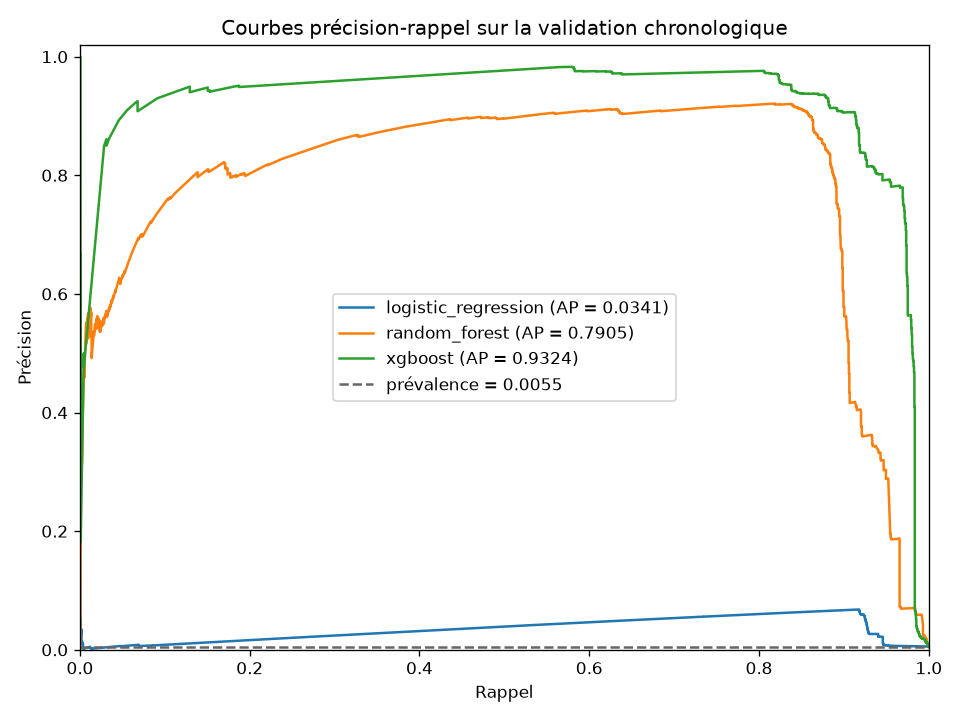

Modèle sélectionné : xgboost
Le test n'était pas ouvert à cette étape : True


In [5]:
rows = []
for model in training["models"]:
    rows.append({
        "modèle": model["family"],
        "pr_auc": model["average_precision"],
        "précision_0,5": model["precision_at_0_5"],
        "rappel_0,5": model["recall_at_0_5"],
        "f1_0,5": model["f1_at_0_5"],
        "secondes": model["train_seconds"],
    })
display(pd.DataFrame(rows))
show_fig("validation_precision_recall.png", "Courbe précision-rappel des trois modèles sur le jeudi. Le modèle retenu est celui dont l'aire sous cette courbe est la plus grande.")
print("Modèle sélectionné :", training["selected_model"])
print("Le test n'était pas ouvert à cette étape :", training["test_scored"] is False)


## 10. Sélection et justification du seuil de décision

Le seuil est choisi après le modèle, uniquement sur les scores du jeudi. Le coût d'une attaque manquée est le double de celui d'une fausse alerte, en taux et non en effectifs, pour que la classe majoritaire n'impose pas le seuil à elle seule. La grille va de 0,01 à 0,99 par centièmes. Le minimum unique est 0,01, au bord de la grille. La grille n'a pas été étendue après avoir vu ce minimum.

| Seuil | TP | FP | FN | TN | Précision | Rappel | F1 | Coût |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0,50 | 1 813 | 89 | 366 | 395 842 | 0,953 | 0,832 | 0,889 | 0,336 |
| 0,01 | 2 001 | 350 | 178 | 395 581 | 0,851 | 0,918 | 0,883 | 0,164 |

Au seuil 0,01, le jeudi gagne du rappel et perd de la précision. Le coût retenu baisse. Ce seuil est bas. Il sera transporté tel quel vers le vendredi, dont la composition d'attaques est différente. C'est une limite du protocole, pas un réglage caché sur le test.


,seuil,tp,fp,fn,tn,precision,recall,f1,cost
0,0.50,1813,89,366,395842,0.953207,0.832033,0.888508,0.336159
1,0.01,2001,350,178,395581,0.851127,0.918311,0.883444,0.164262


Seuil officiel : 0.01


*Coût FPR + 2 × FNR sur la grille du jeudi. Le minimum retenu est le seuil officiel.*

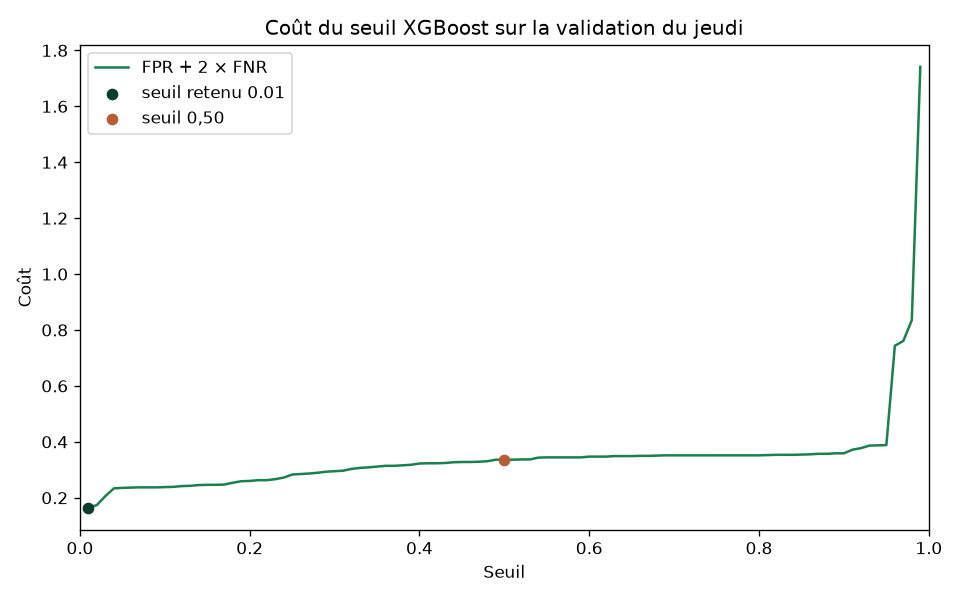

In [6]:
threshold = load_json("xgboost_threshold.json")
chosen = threshold["selected"]
reference = threshold["threshold_0_5"]
display(pd.DataFrame([
    {"seuil": reference["threshold"], **{k: reference[k] for k in ("tp", "fp", "fn", "tn", "precision", "recall", "f1", "cost")}},
    {"seuil": chosen["threshold"], **{k: chosen[k] for k in ("tp", "fp", "fn", "tn", "precision", "recall", "f1", "cost")}},
]))
print("Seuil officiel :", threshold["selected_threshold"])
show_fig("xgboost_threshold_cost.png", "Coût FPR + 2 × FNR sur la grille du jeudi. Le minimum retenu est le seuil officiel.")


## 11. Évaluation finale sur le vendredi

Le vendredi compte 595 723 flux, dont 220 221 attaques. La PR-AUC, indépendante du seuil, vaut 0,806112. Elle baisse par rapport au jeudi, 0,932439. Le modèle rencontre trois familles absentes de l'apprentissage.

| Seuil | Précision | Rappel | F1 | FP | FN | TP |
|---|---:|---:|---:|---:|---:|---:|
| 0,50 | 0,994 | 0,028 | 0,055 | 39 | 214 050 | 6 171 |
| 0,01 | 0,997 | 0,382 | 0,553 | 259 | 136 015 | 84 206 |

La précision monte légèrement de 0,50 à 0,01. Elle ne baisse pas. Le rappel et le F1 montent aussi. Les fausses alertes passent de 39 à 259. Les attaques manquées diminuent de 78 035, et il en reste 136 015.

Au seuil officiel, Bot est entièrement manqué, 0 détection sur 1 953 flux. DDoS est détecté pour 83 050 flux sur 128 013. PortScan l'est pour 1 156 flux sur 90 255. Les 259 fausses alertes sont du trafic BENIGN. Le seuil bas améliore donc surtout la détection d'une partie du DDoS. Il ne fait pas du modèle un détecteur des trois familles du vendredi.

Cinq passages de `predict_proba` sur tout le vendredi durent en moyenne 0,525 s, soit environ 0,88 microseconde par flux. Ce temps ne sert à aucun choix.


PR-AUC vendredi : 0.8061119575266651
Lignes : 595723 {'normal': 375502, 'attack': 220221}


,threshold,precision,recall,f1,fp,fn,tp,tn
0,0.50,0.993720,0.028022,0.054507,39,214050,6171,375463
1,0.01,0.996934,0.382370,0.552740,259,136015,84206,375243


*Erreurs par famille au seuil officiel 0,01.*

,label,rows,tp,fn,fp,tn
0,BENIGN,375502,0,0,259,375243
1,Bot,1953,0,1953,0,0
2,DDoS,128013,83050,44963,0,0
3,PortScan,90255,1156,89099,0,0


Inférence moyenne, secondes : 0.5246877799741924


*Courbe précision-rappel du vendredi pour le XGBoost officiel. L'aire sous la courbe est la PR-AUC publiée.*

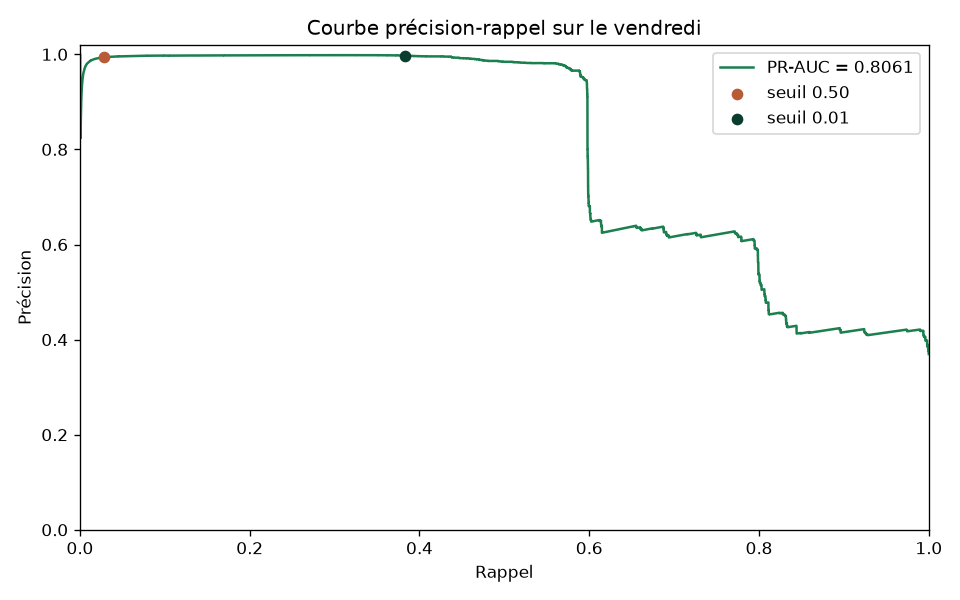

*Matrices de confusion du vendredi aux seuils 0,50 et 0,01. Le second seuil réduit les attaques manquées et augmente peu les fausses alertes, en valeur absolue, parce que le trafic normal est très nombreux.*

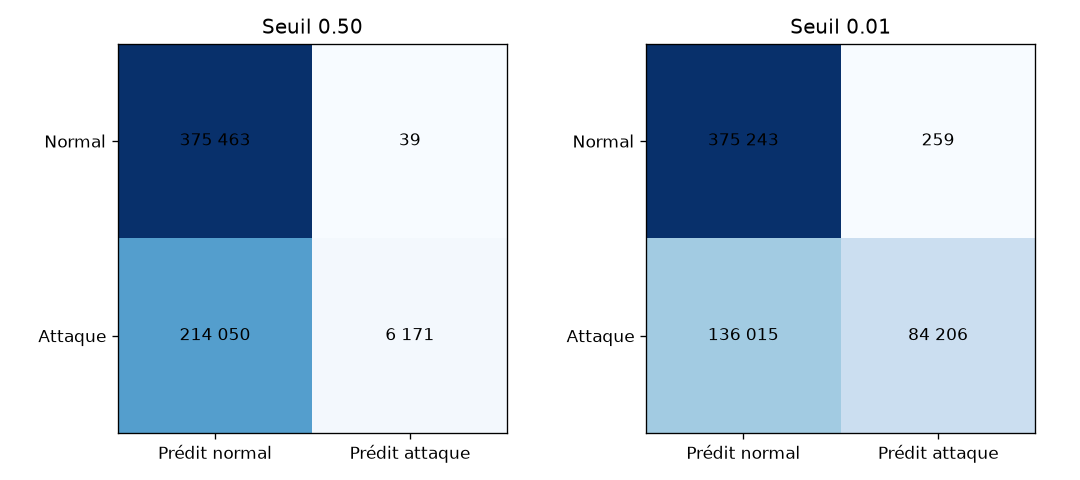

*Fausses alertes et attaques manquées aux deux seuils. Les deux panneaux évitent qu'un effectif cache l'autre.*

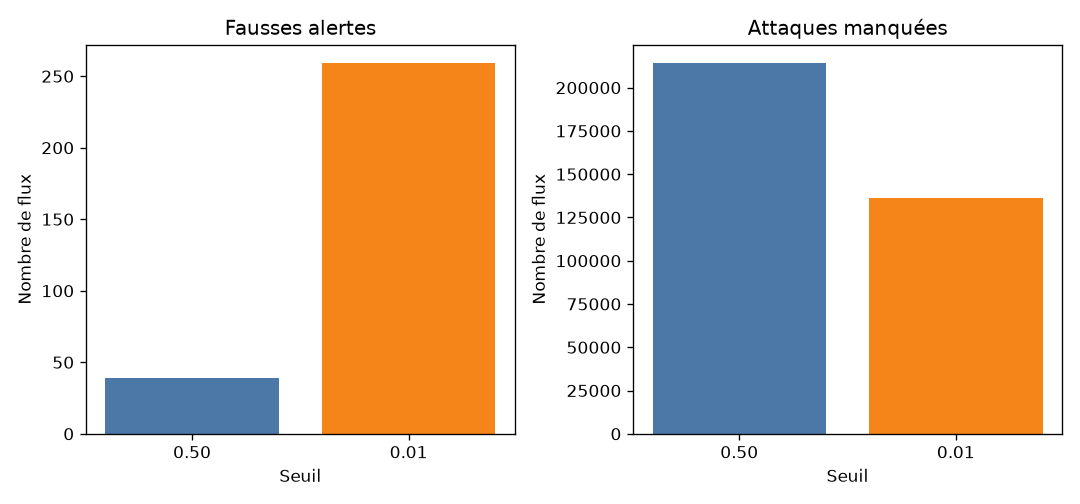

In [7]:
friday = load_json("friday_evaluation.json")
print("PR-AUC vendredi :", friday["pr_auc"])
print("Lignes :", friday["rows"], friday["class_counts"])
display(pd.DataFrame(friday["thresholds"])[
    ["threshold", "precision", "recall", "f1", "fp", "fn", "tp", "tn"]
])
display(Markdown("*Erreurs par famille au seuil officiel 0,01.*"))
display(pd.DataFrame(friday["families_at_official_threshold"]))
print("Inférence moyenne, secondes :", friday["inference"]["full_mean_seconds"])
show_fig("friday_precision_recall.png", "Courbe précision-rappel du vendredi pour le XGBoost officiel. L'aire sous la courbe est la PR-AUC publiée.")
show_fig("friday_confusion_matrices.png", "Matrices de confusion du vendredi aux seuils 0,50 et 0,01. Le second seuil réduit les attaques manquées et augmente peu les fausses alertes, en valeur absolue, parce que le trafic normal est très nombreux.")
show_fig("friday_threshold_comparison.png", "Fausses alertes et attaques manquées aux deux seuils. Les deux panneaux évitent qu'un effectif cache l'autre.")


## 12. Explicabilité globale et comparaison des trois méthodes d'importance

Trois lectures sont comparées. Aucune ne réentraîne le modèle et aucune ne change le seuil.

L'impureté est celle de la forêt déjà entraînée. Elle ne dépend pas du vendredi. La permutation mélange, une variable à la fois, les 595 723 flux du vendredi, et mesure la baisse de PR-AUC. Cinq répétitions, graine 42, sont utilisées. Le calcul est postérieur à l'évaluation finale. Il ne sélectionne aucune variable. La PR-AUC de départ reproduit la valeur publiée, 0,806112. Le SHAP est la moyenne des valeurs absolues déjà calculée sur 2 000 flux du vendredi, graine 42, en log-odds de la classe attaque. L'échantillon respecte le plafond de 2 000 flux.

| Rang | Forêt, impureté | Permutation, vendredi | SHAP, moyenne absolue |
|---:|---|---|---|
| 1 | Packet Length Variance | Destination Port | Destination Port |
| 2 | Packet Length Std | Bwd Packet Length Mean | Bwd Packet Length Std |
| 3 | Bwd Packet Length Std | Bwd Packet Length Std | Init_Win_bytes_backward |
| 4 | Bwd Packet Length Max | Fwd IAT Min | Bwd Packet Length Mean |
| 5 | Destination Port | Bwd Packet Length Max | Init_Win_bytes_forward |
| 6 | Bwd Packet Length Mean | PSH Flag Count | Bwd Packets/s |
| 7 | Max Packet Length | Flow Duration | Fwd IAT Min |
| 8 | Packet Length Mean | Fwd IAT Total | Bwd Packet Length Min |
| 9 | Total Length of Bwd Packets | URG Flag Count | min_seg_size_forward |
| 10 | Average Packet Size | Bwd Packet Length Min | Bwd Packet Length Max |

Destination Port est premier sur les deux lectures du vendredi. Le mélanger fait perdre 0,172 de PR-AUC. La forêt le place cinquième, derrière des tailles de paquets. Six variables sont communes au top 10 de la permutation et du SHAP : le port, trois longueurs de paquets retour, le maximum de ces longueurs, et `Fwd IAT Min`. Les écarts-types des cinq répétitions sont inférieurs à 0,001.

Les tailles globales que la forêt met en tête ne portent pas la PR-AUC du vendredi une fois les longueurs retour présentes. Mélanger `Packet Length Std` fait même légèrement monter la PR-AUC. C'est l'effet de variables corrélées : l'impureté compte plusieurs fois le même signal, la permutation ne le compte qu'une fois. À l'inverse, les deux fenêtres initiales sont hautes au SHAP et seulement 17e et 18e à la permutation. `Bwd Packets/s` est sixième au SHAP et 60e à la permutation. Une forte moyenne absolue sur 2 000 flux ne signifie pas que la colonne porte le classement de toute la journée.

Le graphique en essaim et le graphique en barres décrivent le SHAP de l'échantillon. Ils ne remplacent pas le tableau des trois méthodes.


*Top 10 des trois méthodes. La permutation est celle du vendredi entier. Le SHAP est celui de l'échantillon de 2 000 flux.*  
Source : `outputs\tables\importance_methods_comparison.csv`.

,rank,random_forest,permutation_test,shap_test
0,1,Packet Length Variance,Destination Port,Destination Port
1,2,Packet Length Std,Bwd Packet Length Mean,Bwd Packet Length Std
2,3,Bwd Packet Length Std,Bwd Packet Length Std,Init_Win_bytes_backward
3,4,Bwd Packet Length Max,Fwd IAT Min,Bwd Packet Length Mean
4,5,Destination Port,Bwd Packet Length Max,Init_Win_bytes_forward
5,6,Bwd Packet Length Mean,PSH Flag Count,Bwd Packets/s
6,7,Max Packet Length,Flow Duration,Fwd IAT Min
7,8,Packet Length Mean,Fwd IAT Total,Bwd Packet Length Min
8,9,Total Length of Bwd Packets,URG Flag Count,min_seg_size_forward
9,10,Average Packet Size,Bwd Packet Length Min,Bwd Packet Length Max


*Classement SHAP complet de l'échantillon du vendredi, par moyenne des valeurs absolues.*  
Source : `outputs\tables\shap_global_importance.csv`.

,rank,feature,mean_abs_shap,mean_shap
0,1,Destination Port,3.597745,-3.052439
1,2,Bwd Packet Length Std,2.742078,-0.420192
2,3,Init_Win_bytes_backward,2.574080,-2.541502
3,4,Bwd Packet Length Mean,1.474278,-1.196251
4,5,Init_Win_bytes_forward,1.171452,-1.048709
...,...,...,...,...
56,57,Active Std,0.001407,0.000142
57,58,Active Mean,0.001269,-0.000859
58,59,RST Flag Count,0.000000,0.000000
59,60,ECE Flag Count,0.000000,0.000000


*Chaque point est un flux de l'échantillon. La position est la contribution au log-odds de l'attaque. La couleur indique la valeur de la variable.*

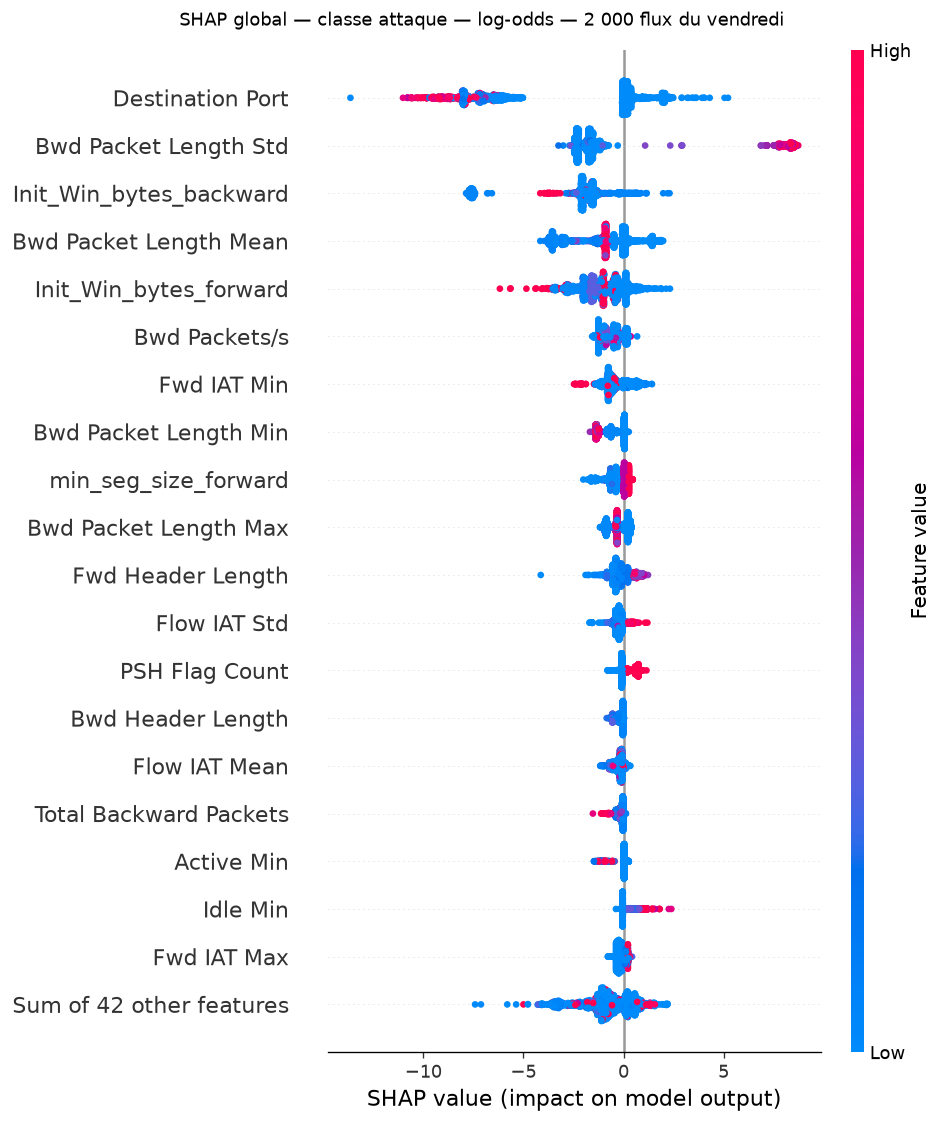

*Moyenne des valeurs absolues SHAP. Le onzième bâton n'est pas une variable : il regroupe le reste, et le dixième rang reste visible.*

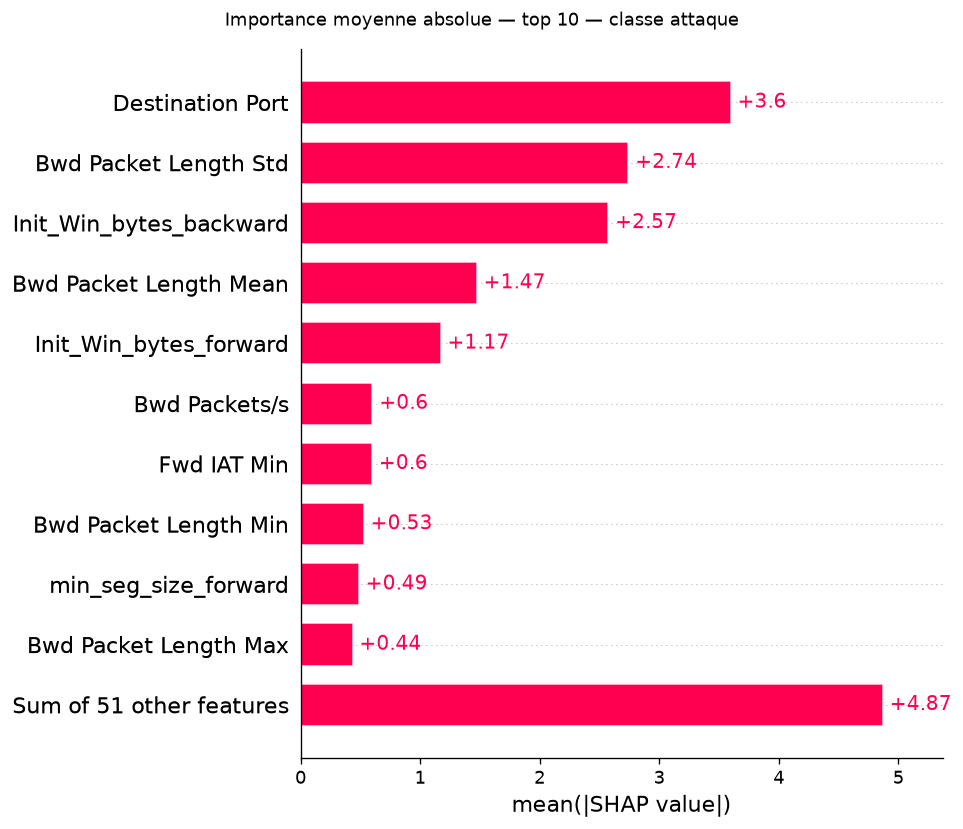

Rôle de la permutation : analyse explicative postérieure à l'évaluation finale
Utilisée pour choisir le modèle : False
PR-AUC de départ : 0.8061119575266651
Répétitions : 5 graine 42


In [8]:
show_csv("importance_methods_comparison.csv", "Top 10 des trois méthodes. La permutation est celle du vendredi entier. Le SHAP est celui de l'échantillon de 2 000 flux.")
show_csv("shap_global_importance.csv", "Classement SHAP complet de l'échantillon du vendredi, par moyenne des valeurs absolues.")
show_fig("shap_summary_beeswarm.png", "Chaque point est un flux de l'échantillon. La position est la contribution au log-odds de l'attaque. La couleur indique la valeur de la variable.")
show_fig("shap_bar_top10.png", "Moyenne des valeurs absolues SHAP. Le onzième bâton n'est pas une variable : il regroupe le reste, et le dixième rang reste visible.")
permutation = load_json("test_permutation_importance.json")
print("Rôle de la permutation :", permutation["role"])
print("Utilisée pour choisir le modèle :", permutation["used_for_model_selection"])
print("PR-AUC de départ :", permutation["baseline_average_precision"])
print("Répétitions :", permutation["n_repeats"], "graine", permutation["seed"])


## 13. Explicabilité locale : les cinq cas SHAP commentés

Les cinq flux ont été choisis sur les scores et les étiquettes du vendredi, avant le calcul des graphiques. Le vrai positif sûr est l'attaque au score le plus élevé. Le vrai positif limite est l'attaque dont le score est juste au-dessus de 0,01. Les deux faux positifs suivent les mêmes règles dans le trafic normal classé à tort comme une attaque. Le faux négatif est l'attaque dont le score est juste au-dessous de 0,01. En cas d'égalité, le plus petit indice du vendredi est gardé.

La valeur de base commune est −0,025 en log-odds. Le seuil 0,01 correspond à environ −4,595. Une contribution positive pousse vers l'attaque. Les graphiques waterfall déjà produits sont affichés avec chaque commentaire. SHAP n'est pas recalculé.

### Vrai positif sûr

Le flux 352055 est une attaque PortScan. Le modèle annonce une attaque, avec un score de 0,99997044 et une marge de 10,427. Le port 80 contribue pour +3,213, une longueur moyenne de paquets retour nulle pour +2,741, et une longueur d'en-tête aller de 160 octets pour +2,730. La fenêtre initiale retour, absente et codée −1, retire 1,551. Elle ne renverse pas la décision. Le plus petit intervalle entre paquets aller vaut 3 microsecondes.

Commentaire d'analyste. Alerte prioritaire, confirmée par l'étiquette PortScan. Le motif est un flux vers le port 80, sans réponse, avec un écart très court. Ce motif n'est pas une signature exclusive du balayage : le faux positif sûr, plus bas, réunit aussi le port 80 et une réponse vide.

### Vrai positif limite

Le flux 532774 est une attaque DDoS. Le score vaut 0,01000577, juste au-dessus du seuil, et la marge vaut −4,595. La fenêtre aller, égale à 256, retire 3,148. Le port 80 ajoute 2,104 et la réponse vide ajoute 1,602. Les deux camps se compensent.

Commentaire d'analyste. Vrai positif fragile. Je ne traiterais pas cette alerte comme un DDoS volumineux confirmé. Le retour est vide, et le score ne dépasse le seuil que de quelques millionièmes. Le flux irait en revue manuelle.

### Faux positif sûr

Le flux 181994 est du trafic normal. Le modèle annonce une attaque avec un score de 0,99961889 et une marge de 7,872. Cinq flux normaux partagent ce score. Le cas retenu est le premier du fichier. Le port 80 et la réponse vide dominent, comme pour le PortScan sûr. Les silences durent ici plusieurs secondes, alors que le vrai positif avait un écart de 3 microsecondes.

Commentaire d'analyste. Fausse alerte. Un silence long sur le port 80 peut être une connexion HTTP inactive. L'étiquette BENIGN le confirme. Le même raccourci, service web sans réponse, produit ici une quasi-certitude injustifiée.

### Faux positif limite

Le flux 182411 est du trafic normal. Le score vaut 0,01012878. La fenêtre aller, 264 octets, retire 3,124. Les intervalles sont réguliers, à 141 microsecondes, et tirent vers le trafic normal. Le port 80 et la réponse vide suffisent à franchir 0,01.

Commentaire d'analyste. Fausse alerte de bord. Je n'ouvrirais pas d'incident. La marge reste très négative. Le classement en alerte vient du seuil bas.

### Faux négatif

Le flux 442290 est une attaque DDoS. Le modèle annonce du trafic normal. Le score vaut 0,00999992, juste sous 0,01. La dispersion des longueurs retour, 4 128 octets, pousse de +8,427 vers l'attaque. La fenêtre retour, égale à 229, retire 7,770. La fenêtre aller, 8 192, retire encore 1,767. Une réponse fournie, de moyenne 2 900 octets, tire ici vers le normal, alors qu'une réponse vide tirait vers l'attaque dans les quatre autres cas.

Commentaire d'analyste. Attaque manquée. Le silence du détecteur ne signifie pas l'absence de signal. Le volume variable de la réponse est bien compté comme un indice d'attaque, puis annulé par une seule valeur de fenêtre. Le score est à moins d'un dix-millionième du seuil.


*Les cinq cas sélectionnés avant le calcul SHAP. Le score du faux négatif est inférieur à 0,01.*  
Source : `outputs\tables\shap_cases.csv`.

,id,present,friday_index,label_original,label,score,n_tied
0,tp_confident,True,352055,PortScan,1,0.999970,1
1,tp_marginal,True,532774,DDoS,1,0.010006,1
2,fp_confident,True,181994,BENIGN,0,0.999619,5
3,fp_marginal,True,182411,BENIGN,0,0.010129,2
4,fn_marginal,True,442290,DDoS,1,0.010000,2


*Vrai positif sûr, PortScan. Les contributions positives du port et de la réponse vide l'emportent.*

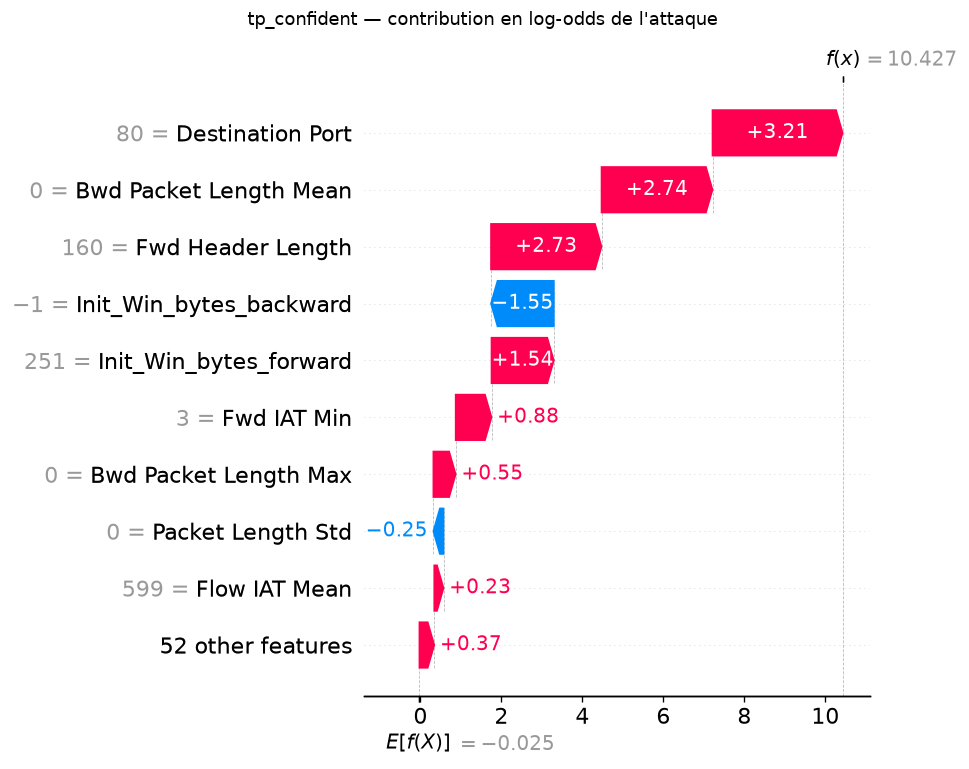

*Vrai positif limite, DDoS. La fenêtre aller retient le score au bord du seuil.*

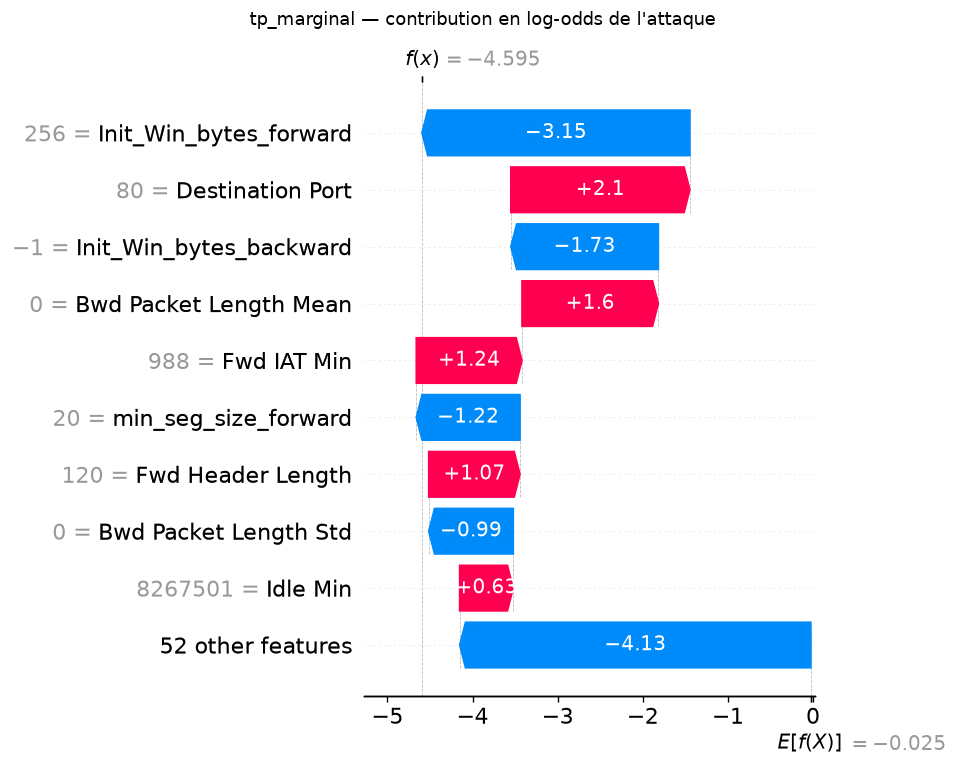

*Faux positif sûr, trafic normal. Le port 80 et la réponse vide produisent une alerte presque certaine.*

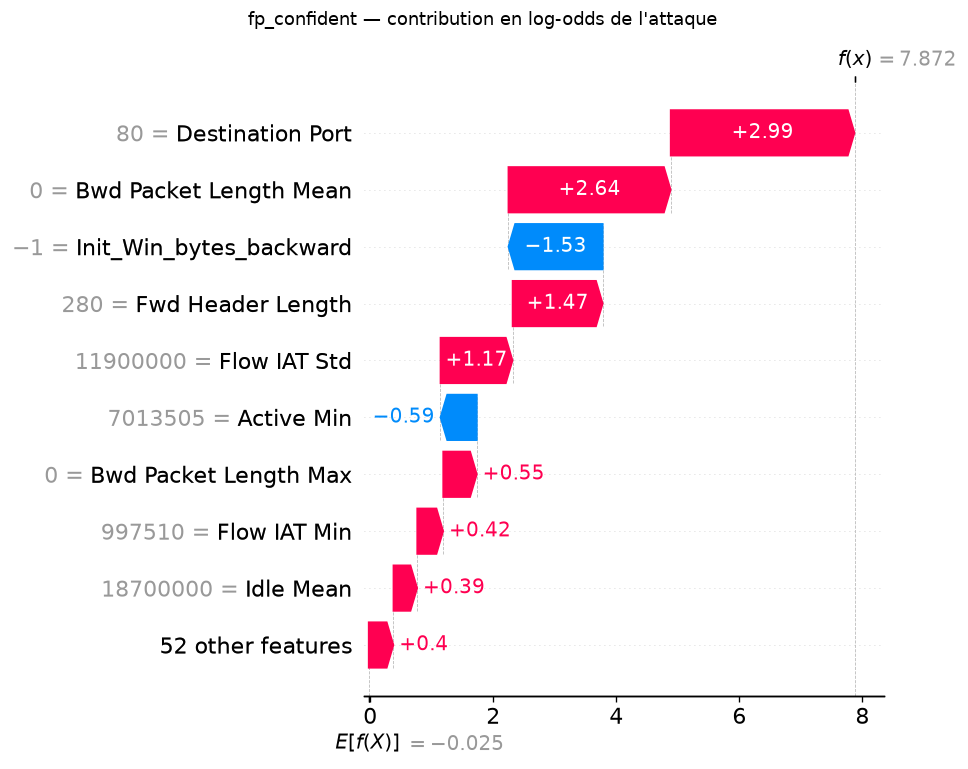

*Faux positif limite, trafic normal. Le dépassement du seuil est très faible.*

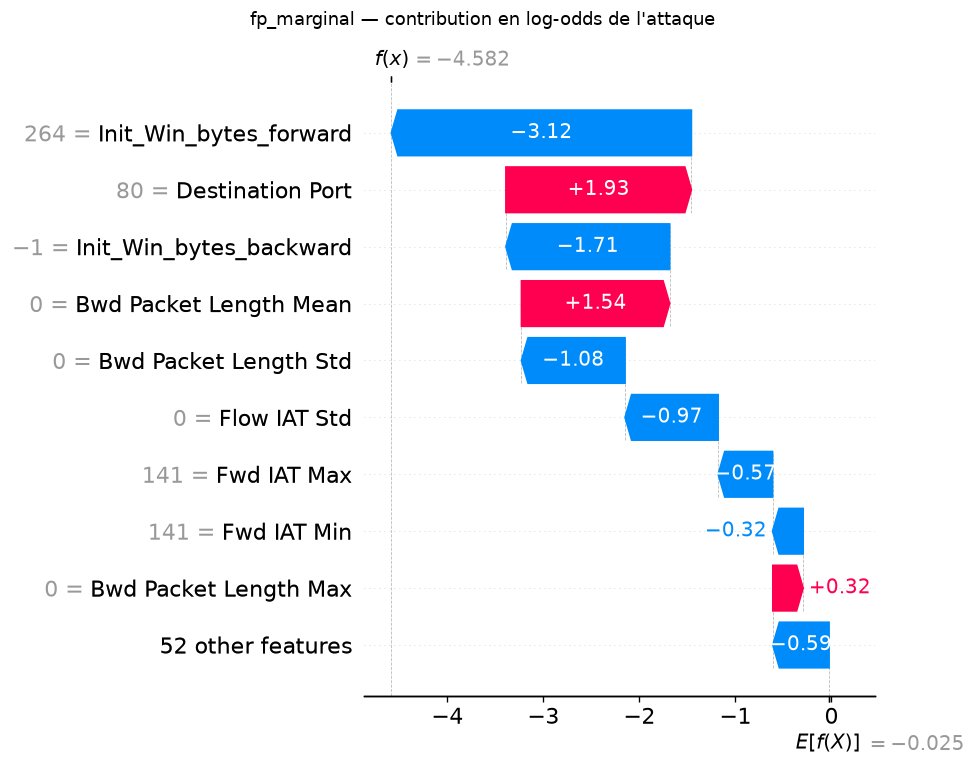

*Faux négatif, DDoS. La fenêtre retour annule la contribution de la réponse dispersée.*

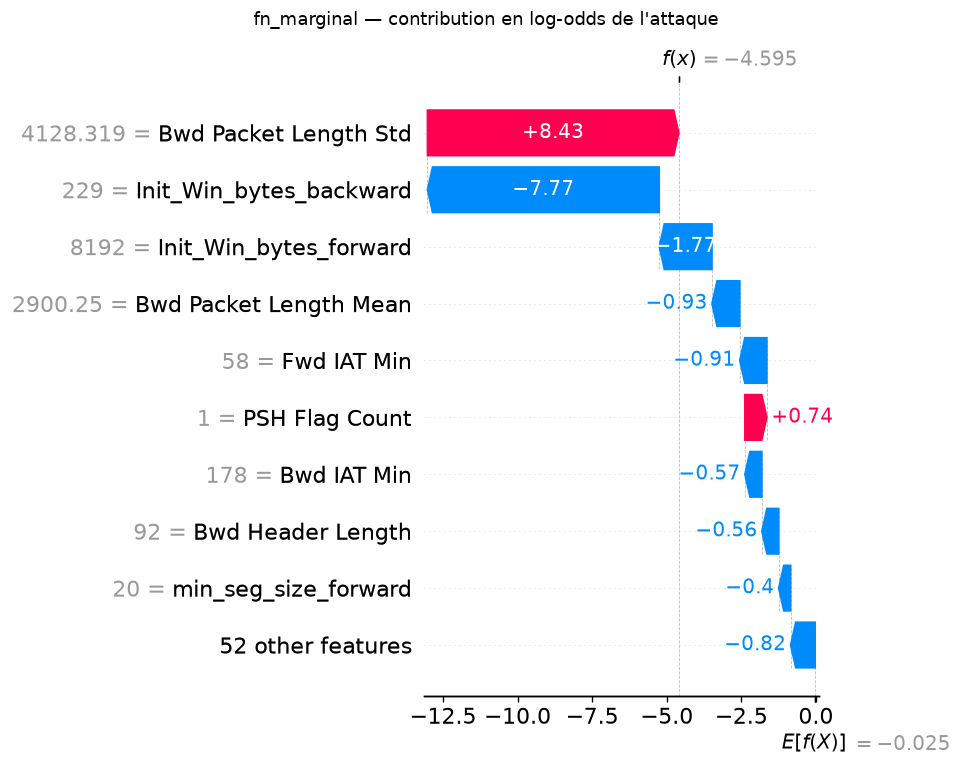

In [9]:
show_csv("shap_cases.csv", "Les cinq cas sélectionnés avant le calcul SHAP. Le score du faux négatif est inférieur à 0,01.")
for name, caption in [
    ("shap_waterfall_tp_confident.png", "Vrai positif sûr, PortScan. Les contributions positives du port et de la réponse vide l'emportent."),
    ("shap_waterfall_tp_marginal.png", "Vrai positif limite, DDoS. La fenêtre aller retient le score au bord du seuil."),
    ("shap_waterfall_fp_confident.png", "Faux positif sûr, trafic normal. Le port 80 et la réponse vide produisent une alerte presque certaine."),
    ("shap_waterfall_fp_marginal.png", "Faux positif limite, trafic normal. Le dépassement du seuil est très faible."),
    ("shap_waterfall_fn_marginal.png", "Faux négatif, DDoS. La fenêtre retour annule la contribution de la réponse dispersée."),
]:
    show_fig(name, caption)


## 14. Audit des dix variables importantes

L'audit lit les dix variables du SHAP d'illustration, puis les confronte à trois classements qui ne utilisent pas le vendredi pour décider : l'impureté de la forêt, la permutation sur un échantillon du jeudi, et le SHAP du jeudi. Une variable n'est suspecte que si elle appartient au top 10 d'au moins deux de ces méthodes et si une raison de domaine est écrite. Le test ne vote pas.

Huit variables satisfont le décompte. Trois ont en plus une raison de domaine. `Destination Port` reproduit le service choisi pour la campagne. Sur le train, 95,5 % des attaques vont vers le port 80, contre 10,3 % du trafic normal. Les Patator FTP et SSH occupent presque exclusivement les ports 21 et 22. Aucune valeur de port n'est impossible. Le port reste un proxy du protocole expérimental, pas une preuve qu'il faudrait l'interdire dans tout détecteur.

`Init_Win_bytes_backward` et `Init_Win_bytes_forward` sont les fenêtres TCP initiales. La valeur −1 est impossible pour une fenêtre. Elle sert de code d'absence et couvre une grande part du trafic normal du train, surtout les flux sans poignée de main TCP. D'autres valeurs, 235 au retour sur le train et 29200 à l'aller pour plusieurs outils, se répètent comme des constantes de machine. Le jeudi ne répète pas 235. Sa constante d'attaque au retour est 28960. La constante change avec la journée.

Les longueurs de paquets retour sont corrélées entre elles. Elles décrivent la taille de la réponse, ce qui peut être un comportement réel. Elles ne sont pas proposées au retrait. `Fwd IAT Min` sépare les attaques lentes des rafales. Quelques valeurs négatives existent, trop rares pour retirer la colonne. `Bwd Packets/s` et `min_seg_size_forward` n'entrent pas dans deux méthodes à la fois avec une raison de domaine suffisante. Elles restent.

Engelen, Rimmer et Joosen jugent l'usage du port de destination discutable, et leur forêt sépare des artefacts de connexion par la fenêtre initiale aller [1]. Notre audit ne reprend pas leurs effectifs. Il s'appuie sur les distributions du train et du jeudi.


*Décision d'audit pour les dix variables du SHAP d'illustration. Une expérience de retrait n'est proposée que pour les trois proxys.*  
Source : `outputs\tables\feature_audit_decision.csv`.

,feature,shap_test_rank,rf_rank,permutation_rank,shap_validation_rank,official_methods_in_top10,domain_reason,proposed_removal_experiment
0,Destination Port,1,5,1,1,3,experimental_setup_proxy,yes
1,Init_Win_bytes_backward,3,16,6,4,2,experimental_setup_proxy,yes
2,Init_Win_bytes_forward,5,23,3,5,2,experimental_setup_proxy,yes
3,Bwd Packet Length Mean,4,6,5,3,3,none,no
4,Bwd Packet Length Std,2,3,27,2,2,none,no
5,Bwd Packet Length Max,10,4,22,9,2,none,no
6,Bwd Packet Length Min,8,35,10,8,2,none,no
7,Fwd IAT Min,7,28,2,6,2,none,no
8,Bwd Packets/s,6,37,57,7,1,none,no
9,min_seg_size_forward,9,36,16,10,1,none,no


*Part du port modal selon la famille. Le port 80 concentre les attaques HTTP du train.*

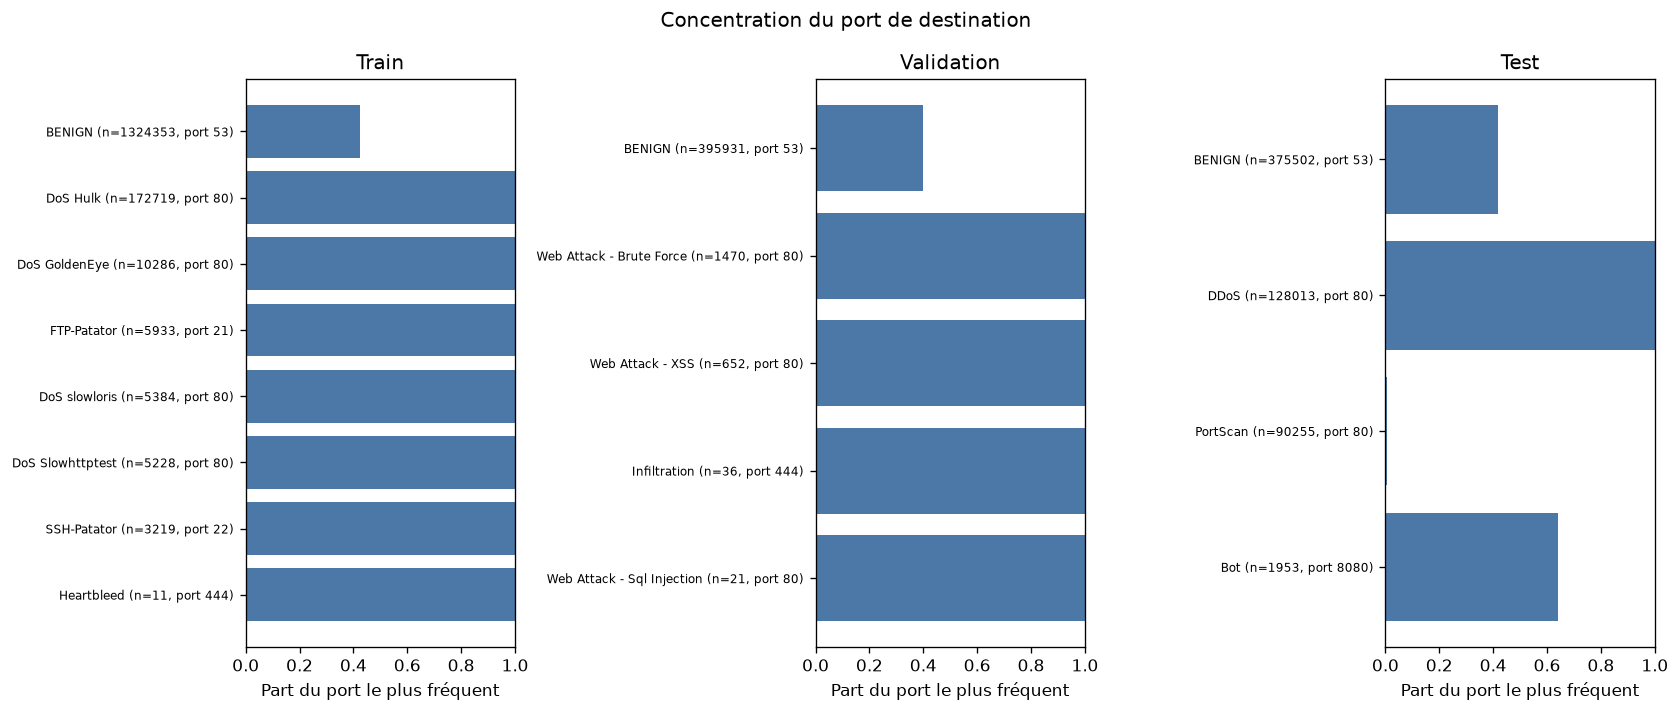

*Part de la valeur la plus fréquente, trafic normal contre attaques.*

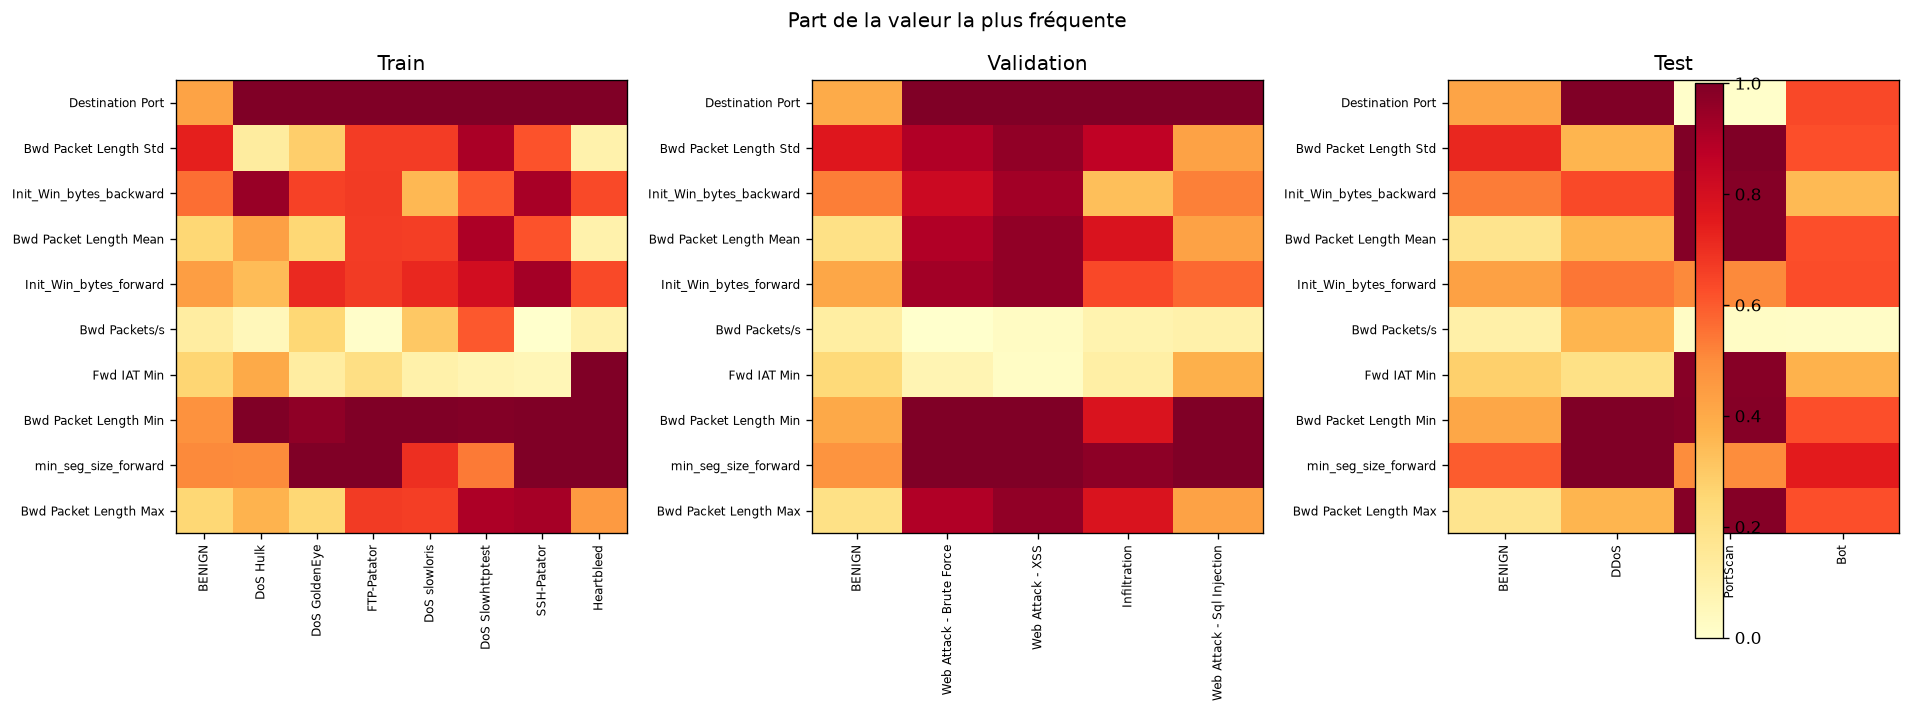

*Part du code −1 dans les fenêtres initiales. Ce code marque surtout l'absence de fenêtre, fréquente dans le trafic normal.*

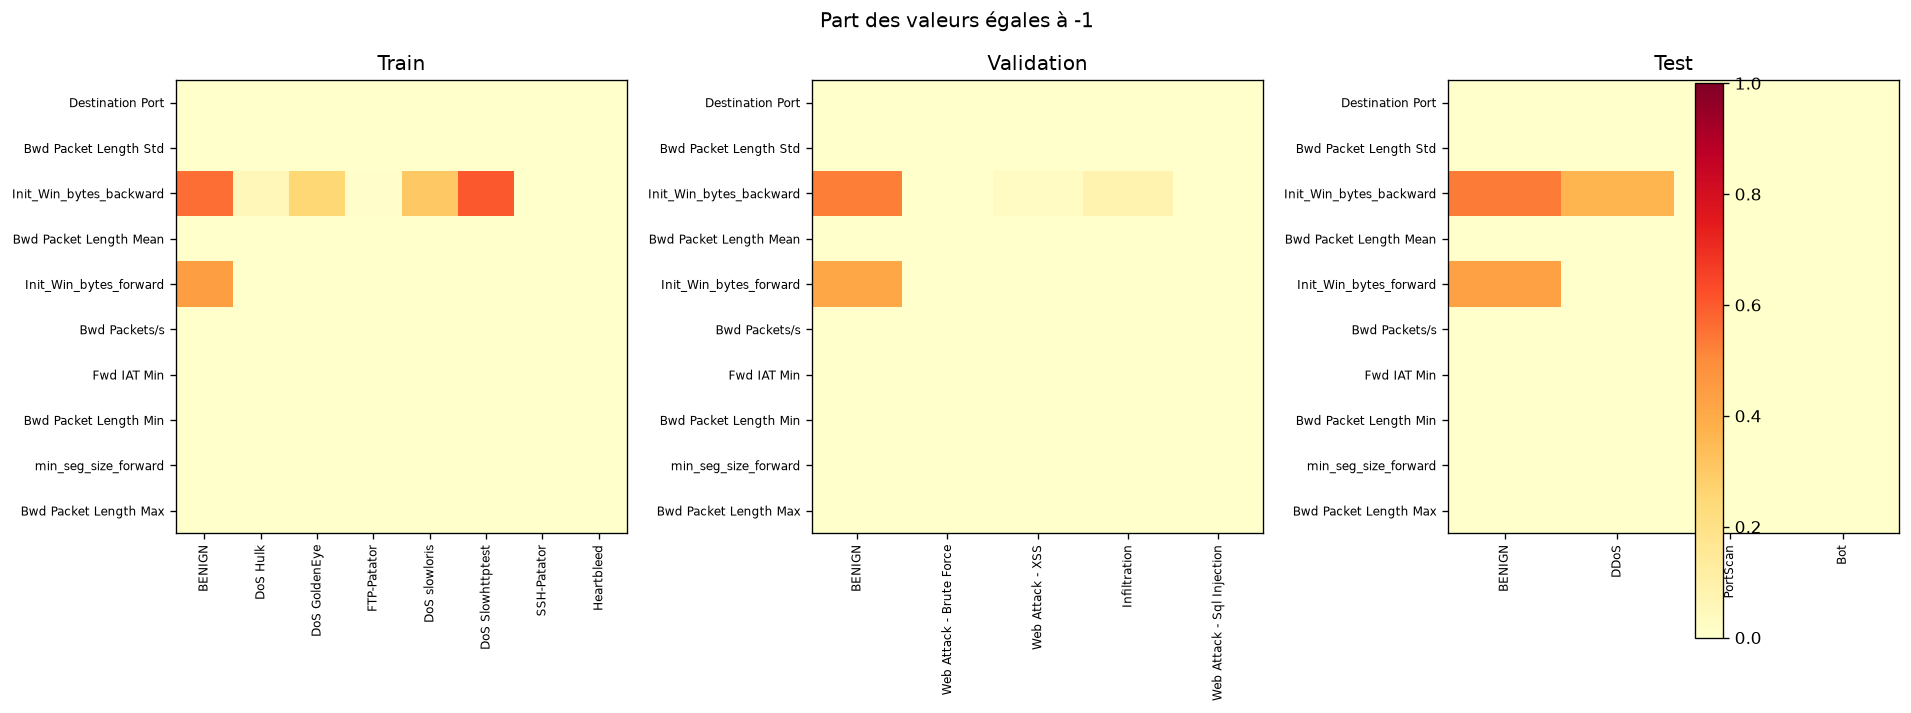

*Part des zéros. Une réponse vide est commune à plusieurs familles, sans être à elle seule un artefact.*

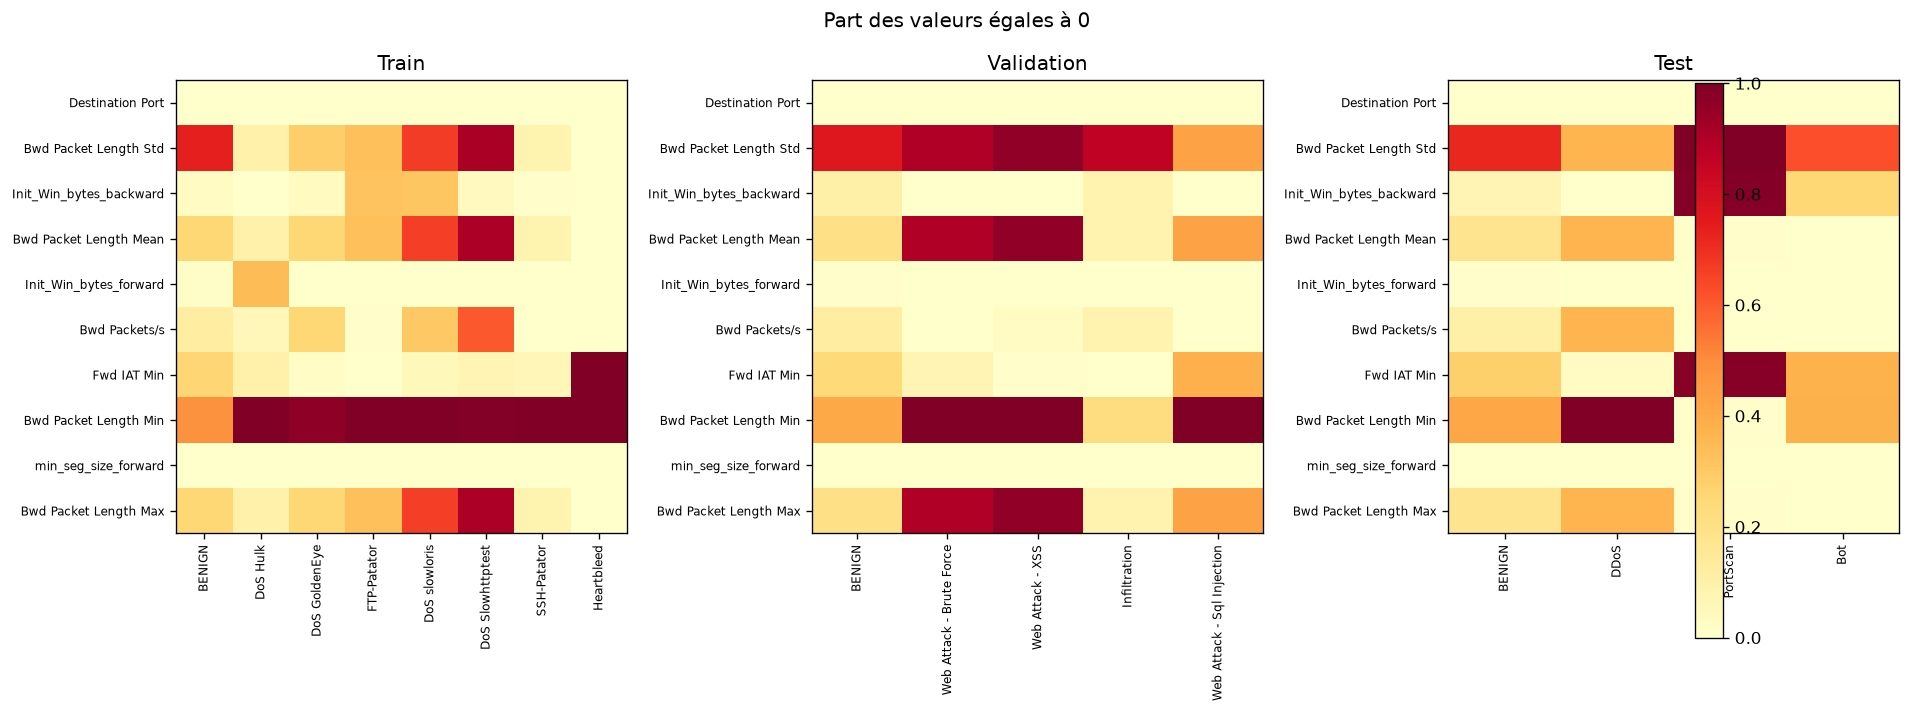

*Rangs des dix variables dans les trois méthodes hors test.*

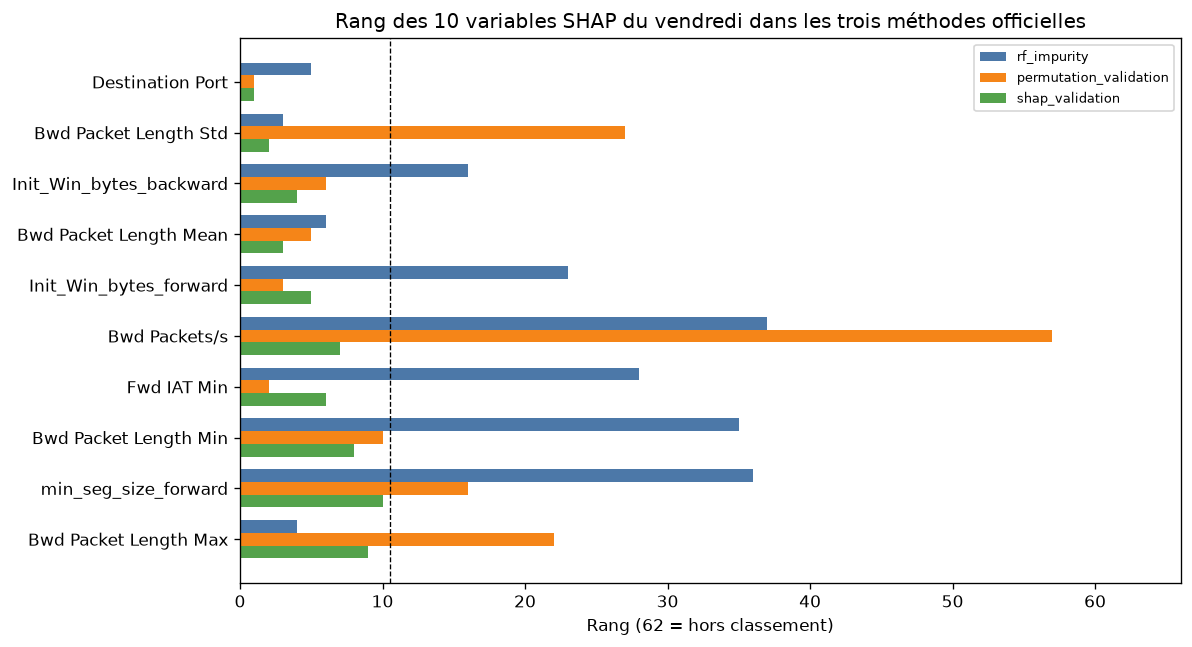

In [10]:
show_csv("feature_audit_decision.csv", "Décision d'audit pour les dix variables du SHAP d'illustration. Une expérience de retrait n'est proposée que pour les trois proxys.")
for name, caption in [
    ("audit_destination_port.png", "Part du port modal selon la famille. Le port 80 concentre les attaques HTTP du train."),
    ("audit_mode_share.png", "Part de la valeur la plus fréquente, trafic normal contre attaques."),
    ("audit_sentinel_neg1.png", "Part du code −1 dans les fenêtres initiales. Ce code marque surtout l'absence de fenêtre, fréquente dans le trafic normal."),
    ("audit_zero_share.png", "Part des zéros. Une réponse vide est commune à plusieurs familles, sans être à elle seule un artefact."),
    ("audit_method_ranks.png", "Rangs des dix variables dans les trois méthodes hors test."),
]:
    show_fig(name, caption)


## 15. Expérience d'ablation des variables suspectes

L'expérience retire ensemble `Destination Port`, `Init_Win_bytes_backward` et `Init_Win_bytes_forward`, puis réentraîne XGBoost. Les hyperparamètres, la graine 42 et le poids de classe sont ceux du modèle officiel. L'imputation est ajustée sur le train seulement. Le seuil n'est pas recherché à nouveau. Le vendredi n'est pas scoré. Le fichier du modèle officiel n'est pas modifié.

Sur le jeudi, la PR-AUC passe de 0,932439 à 0,618205, soit une baisse de 0,314. Cette baisse ne dépend pas du seuil.

| Modèle | Seuil | Précision | Rappel | F1 | FP | FN |
|---|---:|---:|---:|---:|---:|---:|
| Officiel | 0,50 | 0,953 | 0,832 | 0,889 | 89 | 366 |
| Sans les trois variables | 0,50 | 0,639 | 0,637 | 0,638 | 784 | 792 |
| Officiel | 0,01 | 0,851 | 0,918 | 0,883 | 350 | 178 |
| Sans les trois variables | 0,01 | 0,111 | 0,911 | 0,198 | 15 933 | 193 |

Au seuil 0,50, les fausses alertes et les attaques manquées augmentent toutes les deux. Au seuil 0,01, le rappel reste proche et les fausses alertes passent de 350 à 15 933, soit 4,02 % du trafic normal du jeudi contre 0,088 % auparavant. L'apprentissage dure 21,8 s, contre 20,9 s.

La chute dit que ces trois variables portaient une grande part du classement sur le jeudi. Elle ne dit pas laquelle des trois, parce qu'elles ont été retirées ensemble. Le jeudi est une validation de transfert, surtout des attaques web vers le port 80, avec une fenêtre qui se répète. La baisse mesure ce raccourci sur cette journée. Le seuil 0,01 avait été choisi pour les scores du modèle officiel. Le garder tel quel explique une partie de l'afflux d'alertes. Le modèle d'ablation ne devient pas le résultat officiel.


In [11]:
ablation = load_json("ablation_suspect_features.json")
print("Variables retirées :", ablation["removed_features"])
print("Vendredi scoré :", ablation["friday_scored"])
print("Modèle officiel modifié :", ablation["official_model_modified"])
print("PR-AUC officielle :", ablation["original"]["pr_auc"])
print("PR-AUC sans les trois variables :", ablation["ablated"]["pr_auc"])
print("Temps d'apprentissage, secondes :", ablation["original"]["train_seconds"], ablation["ablated"]["train_seconds"])
show_csv("ablation_suspect_features.csv", "Comparaison sur le jeudi, aux seuils 0,50 et 0,01. Le second seuil n'a pas été réoptimisé.")


Variables retirées : ['Destination Port', 'Init_Win_bytes_backward', 'Init_Win_bytes_forward']
Vendredi scoré : False
Modèle officiel modifié : False
PR-AUC officielle : 0.9324393719922159
PR-AUC sans les trois variables : 0.6182053717528053
Temps d'apprentissage, secondes : 20.921240100171417 21.845644500106573


*Comparaison sur le jeudi, aux seuils 0,50 et 0,01. Le second seuil n'a pas été réoptimisé.*  
Source : `outputs\tables\ablation_suspect_features.csv`.

,model,threshold,pr_auc,precision,recall,f1,tn,fp,fn,tp
0,official,0.50,0.932439,0.953207,0.832033,0.888508,395842,89,366,1813
1,official,0.01,0.932439,0.851127,0.918311,0.883444,395581,350,178,2001
2,without_three_features,0.50,0.618205,0.638876,0.636531,0.637701,395147,784,792,1387
3,without_three_features,0.01,0.618205,0.110832,0.911427,0.197632,379998,15933,193,1986


,model,threshold,pr_auc,precision,recall,f1,tn,fp,fn,tp
0,official,0.50,0.932439,0.953207,0.832033,0.888508,395842,89,366,1813
1,official,0.01,0.932439,0.851127,0.918311,0.883444,395581,350,178,2001
2,without_three_features,0.50,0.618205,0.638876,0.636531,0.637701,395147,784,792,1387
3,without_three_features,0.01,0.618205,0.110832,0.911427,0.197632,379998,15933,193,1986


## 16. Étude de stabilité des explications

Deux questions sont séparées. Aucune ne lit le vendredi et aucune ne modifie le modèle officiel.

L'expérience A réentraîne trois fois sur tout le train officiel, avec les graines 42, 7 et 123. Les hyperparamètres restent figés, dont `subsample=1` et `colsample_bytree=1`. Les trois classements SHAP, sur le même échantillon de 2 000 flux du jeudi, sont identiques. Le Jaccard du top 10 vaut 1 et le Spearman des 61 rangs vaut 1. L'écart entre les moyennes absolues est nul. Ce n'est pas l'accord de trois modèles différents. À ces deux réglages, chaque arbre voit toutes les lignes et toutes les variables. La graine n'a plus rien à tirer.

L'expérience B ne crée pas un nouveau découpage des journées. Pour les graines 1001, 1002 et 1003, elle retire 30 % des flux du train officiel, de façon stratifiée sur l'étiquette d'origine. Aucun flux du jeudi ni du vendredi n'entre dans l'apprentissage. L'imputation et `scale_pos_weight` sont ajustés sur le sous-échantillon seul. Le même échantillon du jeudi sert aux explications.

| Paire de sous-échantillons | Jaccard du top 10 | Spearman des 61 rangs |
|---|---:|---:|
| 1001 / 1002 | 0,818 | 0,911 |
| 1001 / 1003 | 0,818 | 0,903 |
| 1002 / 1003 | 0,818 | 0,898 |

Le cœur tient. Destination Port reste premier, `Bwd Packet Length Std` deuxième. Les deux fenêtres et `Bwd Packet Length Mean` restent dans les cinq premiers. `Fwd IAT Min` passe du rang 6, sur le train complet, aux rangs 9, 9 et 12. `Fwd Header Length` entre au rang 10 dans deux sous-échantillons. Le classement est donc stable dans son cœur, et mobile à la frontière du top 10 lorsque les flux d'apprentissage changent.

L'échantillon du jeudi contient peu d'attaques. Un rang de bord peut bouger sans que le sens du modèle change. Cette expérience ne mesure pas un autre découpage chronologique.


Vendredi lu : False
Modèle officiel modifié : False


,left,right,jaccard_top10,spearman_full_ranking
0,graine-42,graine-7,1.0,1.0
1,graine-42,graine-123,1.0,1.0
2,graine-7,graine-123,1.0,1.0


,left,right,jaccard_top10,spearman_full_ranking
0,sous-echantillon-1001,sous-echantillon-1002,0.818182,0.911211
1,sous-echantillon-1001,sous-echantillon-1003,0.818182,0.903173
2,sous-echantillon-1002,sous-echantillon-1003,0.818182,0.897726


*Dix premières variables de chaque graine et de chaque sous-échantillon.*  
Source : `outputs\tables\stability_top10.csv`.

,run_id,experiment,rank,feature,mean_abs_shap
0,graine-42,model_seed,1,Destination Port,3.817221
1,graine-42,model_seed,2,Bwd Packet Length Std,1.936927
2,graine-42,model_seed,3,Init_Win_bytes_backward,1.794023
3,graine-42,model_seed,4,Bwd Packet Length Mean,1.785862
4,graine-42,model_seed,5,Init_Win_bytes_forward,1.017026
5,graine-42,model_seed,6,Fwd IAT Min,0.683806
6,graine-42,model_seed,7,Bwd Packet Length Min,0.670468
7,graine-42,model_seed,8,Bwd Packets/s,0.658526
8,graine-42,model_seed,9,Bwd Packet Length Max,0.509046
9,graine-42,model_seed,10,min_seg_size_forward,0.358776


*Rang des variables présentes dans au moins un top 10. Une couleur claire indique un rang élevé.*

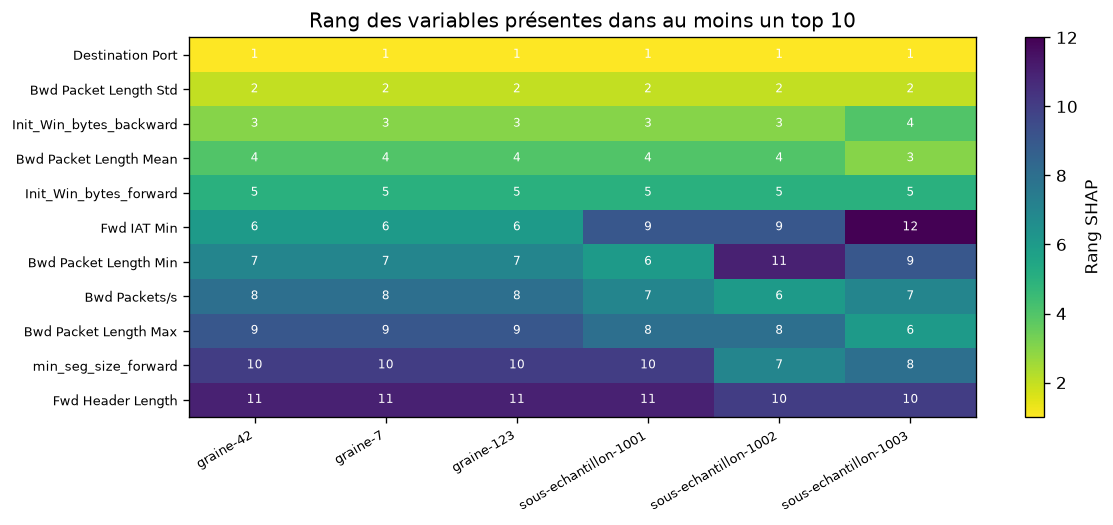

In [12]:
stability = load_json("stability_explanations.json")
print("Vendredi lu :", stability["friday_read"])
print("Modèle officiel modifié :", stability["official_model_modified"])
display(pd.DataFrame(stability["pairs_a"]))
display(pd.DataFrame(stability["pairs_b"]))
show_csv("stability_top10.csv", "Dix premières variables de chaque graine et de chaque sous-échantillon.")
show_fig("stability_rank_heatmap.png", "Rang des variables présentes dans au moins un top 10. Une couleur claire indique un rang élevé.")


## 17. Analyse critique et limites

Le modèle officiel détecte une partie du DDoS du vendredi et manque le botnet en entier, ainsi que la grande majorité du balayage de ports. La PR-AUC de 0,806 décrit cette généralisation incomplète. Elle est plus honnête que l'accuracy, parce que les deux classes sont déséquilibrées et que leur proportion change d'un jour à l'autre.

Plusieurs limites tiennent au jeu. Les attaques sont simulées, souvent avec un outil et une configuration. Engelen, Rimmer et Joosen montrent que des flux sans charge utile sont étiquetés comme des attaques, que des appendices TCP représentent 25,9 % du jeu publié, et que l'outil DoS Hulk de la capture est mal implémenté [1]. Notre dérivé n'a pas corrigé ces défauts. Il a retiré les copies exactes, les profils aux étiquettes contradictoires, la colonne dupliquée, et il a neutralisé les infinis. Le résultat officiel reste donc conditionné par la collecte.

Le choix du modèle et du seuil sur le jeudi n'est pas une estimation impartiale. Le jeudi contient d'autres familles que le train, et le vendredi encore d'autres. Le seuil 0,01 est au bord de la grille. Transporté vers une autre composition d'attaques, il produit beaucoup d'alertes dès que la distribution des scores change, comme l'ablation le montre.

Les explications ont leurs propres limites. Des variables corrélées se partagent le crédit. Le SHAP local porte sur le log-odds, pas sur la probabilité. L'échantillon global compte 2 000 flux. La permutation du vendredi voit toute la journée, mais elle ne doit pas servir à retirer une variable après avoir vu le test. Les cinq cas illustrent des mécanismes. Ils ne résument pas les 136 015 attaques manquées.

La stabilité selon la graine est réelle au sens où le classement ne change pas, et elle est peu informative au sens où les hyperparamètres ne laissent aucun aléa d'échantillonnage. La stabilité selon les flux d'apprentissage est partielle. Elle ne remplace pas un second découpage chronologique, qui n'existe pas sans faire entrer le futur dans l'apprentissage.

Enfin, les rapports de phase gardent l'état du moment où ils ont été écrits. Lorsque deux chiffres de nettoyage diffèrent, l'inspection des CSV bruts et le fichier dérivé doivent être nommés. Les deux séries validées sont 308 381 copies et 1 358 jetons manquants d'une part, 302 757 copies retirées et 351 jetons conservés d'autre part.


## 18. Conclusion générale

Le détecteur officiel est un XGBoost appris du lundi au mercredi, avec un seuil de 0,01 choisi sur le jeudi. Sur le vendredi, sa PR-AUC vaut 0,806112. Au seuil officiel, la précision vaut 0,997 et le rappel 0,382. Il détecte une partie du DDoS, presque aucun PortScan, et aucun Bot.

Les explications disent que ce score mélange des signaux de trafic et des particularités du jeu. Le port de destination et les fenêtres initiales dominent plusieurs classements. Les retirer ensemble fait chuter la PR-AUC du jeudi de 0,932439 à 0,618205. Les longueurs de paquets retour et le délai minimal aller restent des candidats plus plausibles, et ils résistent mieux à la comparaison entre méthodes. Le modèle apprend donc les deux. Il reconnaît des formes de réponse et de rythme, et il s'appuie aussi sur le scénario de collecte.

Cette conclusion ne remplace pas le modèle officiel par le modèle d'ablation. Elle fixe ce que l'on peut attendre de lui. Une alerte vers le port 80, sans réponse, doit être lue comme un raccourci possible. Une absence d'alerte sur un flux à la réponse volumineuse peut venir d'une fenêtre qui annule le reste du signal. L'analyste a besoin de ces deux lectures, parce que le score seul ne les distingue pas.


## 19. Bibliographie

[1] Engelen, G., Rimmer, V. et Joosen, W. (2021). Troubleshooting an Intrusion Detection Dataset: the CICIDS2017 Case Study. *2021 IEEE Security and Privacy Workshops (SPW)*, p. 7-12. DOI : [10.1109/SPW53761.2021.00009](https://doi.org/10.1109/SPW53761.2021.00009).

[2] Engelen, G., Rimmer, V. et Joosen, W. Documentation étendue du même article. [https://intrusion-detection.distrinet-research.be/WTMC2021/extended_doc.html](https://intrusion-detection.distrinet-research.be/WTMC2021/extended_doc.html).

Les effectifs, courbes et tableaux de ce notebook viennent des fichiers de `outputs/metrics`, `outputs/tables` et `outputs/figures`. Les rapports sources restent dans `docs/`.


In [13]:
preparation = load_json("preparation_manifest.json")
methodology = load_json("methodology_audit.json")
training = load_json("training_validation.json")
friday = load_json("friday_evaluation.json")
ablation = load_json("ablation_suspect_features.json")
stability = load_json("stability_explanations.json")
permutation = load_json("test_permutation_importance.json")

assert methodology["exact_duplicates"]["extra_rows"] == 308381
assert methodology["column_anomalies"]["missing_flow_bytes"] == 1358
assert preparation["later_exact_copies_removed"] == 302757
assert preparation["missing_tokens_preserved_as_missing"] == 351
assert preparation["kept_rows"] == 2520966
assert preparation["infinity_cells_replaced_with_missing"] == 2773
assert preparation["audit"]["missing_cells"] == 3124
assert training["selected_model"] == "xgboost"
xgboost = next(model for model in training["models"] if model["family"] == "xgboost")
assert abs(xgboost["average_precision"] - 0.9324393719922159) < 1e-15
assert abs(friday["pr_auc"] - 0.8061119575266651) < 1e-15
assert friday["thresholds"][1]["threshold"] == 0.01
assert ablation["friday_scored"] is False
assert abs(ablation["ablated"]["pr_auc"] - 0.6182053717528053) < 1e-15
assert stability["friday_read"] is False
assert permutation["used_for_model_selection"] is False
assert abs(permutation["baseline_average_precision"] - friday["pr_auc"]) < 1e-6
required = [
    FIGURES / "shap_waterfall_tp_confident.png",
    FIGURES / "shap_waterfall_tp_marginal.png",
    FIGURES / "shap_waterfall_fp_confident.png",
    FIGURES / "shap_waterfall_fp_marginal.png",
    FIGURES / "shap_waterfall_fn_marginal.png",
    FIGURES / "stability_rank_heatmap.png",
    TABLES / "importance_methods_comparison.csv",
]
missing = [str(path.relative_to(ROOT)) for path in required if not path.exists()]
assert not missing, missing
print("Contrôles de cohérence réussis.")
print("Les expériences coûteuses n'ont pas été relancées.")


Contrôles de cohérence réussis.
Les expériences coûteuses n'ont pas été relancées.
